# Willett et al. 2021, model example: decoding the handwritten character

A small tutorial that decodes **which of the 31 characters** T5 attempted to handwrite (a-z plus space, comma, apostrophe, period, question mark), from the go-period neural features. This is the single-character building block of the paper's brain-to-text system (the full system adds a temporal RNN and a language model over sentences).

- **Input**: `threshold_crossings` over the 1 s go period (`NeuralFeatureExtractor` on `SpikeCounts`), `(192 channels, 100 bins)` per trial.
- **Target**: the character's `code` (1-31) through a `LabelEncoder`, 31 classes (chance = 1/31 = 3.2%).
- **Data**: all 10 `singleLetters` sessions for T5 (3,627 trials). The last session, t5.2020.01.15, is the test set, and the last block of the session before it is the validation set.

**The handwriting signal is temporal.** The within-window time course decodes better than the per-channel mean, because different characters trace different pen paths over the go period.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

import neuralset as ns
import neuralshed.events  # noqa: F401, registers the custom event types
from neuralshed.extractors import NeuralFeatureExtractor
from neuralshed.datasets.willet_2021 import study, utils
from neuralshed.datasets.utils import dataset_dir
from neuralset.extractors import LabelEncoder

pd.set_option("display.width", 200)
torch.manual_seed(0)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("willet_2021") / "data"
s = study.Willett2021Handwriting(path=root)
s.download()

# 100 Hz, 10 ms bins
FS = 100.0

# the 1 s go period
WIN_S = 1.0

# the last day, held out as the test set
TEST_SESSION = "t5.2020.01.15"

# the day before it, whose last block is the validation set
VAL_SESSION = "t5.2020.01.13"

EPOCHS = 150

# extractor disk cache
CACHE = dict(folder=dataset_dir("willet_2021") / "cache", keep_in_ram=False)

# class k is code k + 1, in utils.CHAR_LIST order
GLYPHS = [utils.CHAR_CLASS_TO_GLYPH[c] for c in utils.CHAR_LIST]
DISPLAY = [g if g != " " else "_" for g in GLYPHS]
K = len(GLYPHS)
CHANCE = 1 / K


def center_blocks(X, blocks):
    """Subtract each block's mean window, a label-free statistic of that block."""
    out = X.copy()
    for block in np.unique(blocks):
        rows = blocks == block
        out[rows] -= X[rows].mean(axis=(0, 2), keepdims=True)
    return out


def zscore(X, train):
    """z-score every feature with the training statistics."""
    mu = X[train].mean(0)
    sd = X[train].std(0) + 1e-6
    return (X - mu) / sd

2026-10-13 16:29:14 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/willet_2021/data/Willett2021Handwriting.


2026-10-13 16:29:20 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/willet_2021/data/Willett2021Handwriting (skipped 0 non-owned items).


## 1. Build the input windows

Trigger one window per `Character` (the pilot `doNothing` rest is an `Action`, so a `Character` trigger leaves it out), read the `(192, 100)` threshold-crossing window over the go period, and read each window's class from `code`. Each window keeps its session and block for the split.

In [2]:
events = study.Willett2021Handwriting(path=root, query="task == 'singleLetters'").run()
segmenter = ns.dataloader.Segmenter(
    extractors={
        "input": NeuralFeatureExtractor(
            target_unit="Hz",
            event_types="SpikeCounts",
            frequency=FS,
            infra=CACHE,
        ),
        "target": LabelEncoder(
            event_types="Character",
            event_field="code",
            aggregation="trigger",
        ),
    },
    trigger_query="type == 'Character'",
    start=0.0,
    duration=WIN_S,
)
dataset = segmenter.apply(events)
dataset.prepare()
batch = dataset.load_all()

# (N, 192, 100)
X = batch.data["input"].float().numpy()
y = batch.data["target"].ravel().numpy()
trials = pd.DataFrame(
    {
        "session": [sg.trigger.extra["session"] for sg in batch.segments],
        "block": [sg.trigger.timeline for sg in batch.segments],
        "code": [int(sg.trigger.extra["code"]) for sg in batch.segments],
    }
)
# the encoder sorts the 31 codes, so class k is code k + 1
assert (trials.code - 1 == y).all()
print("windows:", X.shape, "| classes:", K, "| chance: %.3f" % CHANCE)
print("labels:", "".join(DISPLAY))

2026-10-13 16:29:24 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-10-13 16:29:24 - INFO - neuralset.dataloader:222 - Preparing extractor: LabelEncoder


windows: (3627, 192, 100) | classes: 31 | chance: 0.032
labels: abcdefghijklmnopqrstuvwxyz_,'.?


## 2. Headline: decode 31 characters

A small MLP on the **time-resolved** window (flattened to `192 x 100 = 19,200` features). Each block's mean window is subtracted first, a label-free statistic computed in every block, test blocks included, and the features are then z-scored with the training statistics. The MLP early-stops on the validation block and is scored once on the held-out session.

In [3]:
last_val_block = trials[trials.session == VAL_SESSION].block.iloc[-1]
split = np.where(
    trials.session == TEST_SESSION,
    "test",
    np.where(trials.block == last_val_block, "val", "train"),
)
tr = split == "train"
va = split == "val"
te = split == "test"
print({name: int((split == name).sum()) for name in ("train", "val", "test")})

Xc = center_blocks(X, trials.block.to_numpy())
Xf = zscore(Xc.reshape(len(Xc), -1), tr)
Xtr = torch.tensor(Xf[tr], dtype=torch.float32)
ytr = torch.tensor(y[tr])
Xva = torch.tensor(Xf[va], dtype=torch.float32)
yva = torch.tensor(y[va])
Xte = torch.tensor(Xf[te], dtype=torch.float32)
yte = torch.tensor(y[te])

mlp = nn.Sequential(
    nn.Linear(Xf.shape[1], 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, K),
)
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-3)
lossf = nn.CrossEntropyLoss()

best_acc = 0.0
best_state = None
for epoch in range(EPOCHS):
    mlp.train()
    opt.zero_grad()
    lossf(mlp(Xtr), ytr).backward()
    opt.step()
    mlp.eval()
    with torch.no_grad():
        acc = (mlp(Xva).argmax(1) == yva).float().mean().item()
    if acc >= best_acc:
        best_acc = acc
        best_state = {k: v.clone() for k, v in mlp.state_dict().items()}
mlp.load_state_dict(best_state)

with torch.no_grad():
    test_pred = mlp(Xte).argmax(1).numpy()
test_acc = (test_pred == y[te]).mean()
print(f"validation accuracy: {best_acc:.3f}")
print(f"test accuracy ({TEST_SESSION}): {test_acc:.3f}   (chance {CHANCE:.3f})")

{'train': 3162, 'val': 155, 'test': 310}


validation accuracy: 0.794
test accuracy (t5.2020.01.15): 0.700   (chance 0.032)


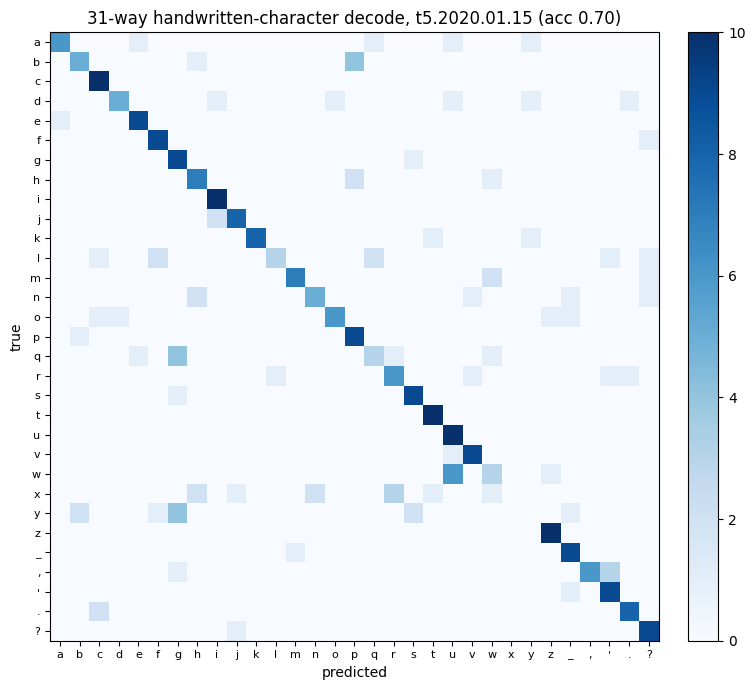

In [4]:
# confusion matrix on the held-out session
C = confusion_matrix(y[te], test_pred, labels=range(K))

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(C, cmap="Blues")
ax.set(
    xticks=range(K),
    yticks=range(K),
    xticklabels=DISPLAY,
    yticklabels=DISPLAY,
    xlabel="predicted",
    ylabel="true",
    title=f"31-way handwritten-character decode, {TEST_SESSION} (acc {test_acc:.2f})",
)
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.setp(ax.get_yticklabels(), fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 3. The signal is temporal

The paper's central representational fact: each attempted character produces a distinct **time course** of neural activity (it mirrors the pen trajectory). We compare two views of the *same* window with a linear decoder fit on the training trials and scored on the validation block:

- **mean-pooled**: average each channel over the go period, `(192,)`. Throws away the time course.
- **time-resolved**: the full `(192 x 100)` window flattened, `(19200,)`. Keeps it.

  mean-pooled    validation acc=0.684


  time-resolved  validation acc=0.794


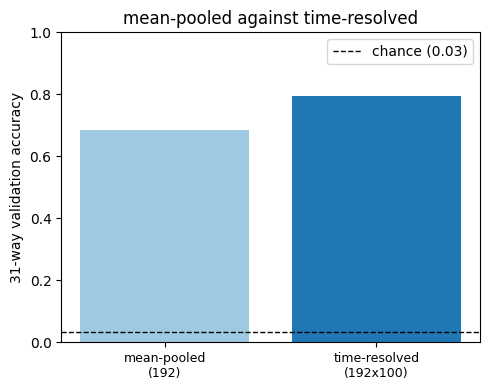

In [5]:
views = {
    "mean-pooled\n(192)": zscore(Xc.mean(2), tr),
    "time-resolved\n(192x100)": Xf,
}
accs = {}
for name, Z in views.items():
    clf = LogisticRegression(max_iter=3000, C=0.003)
    clf.fit(Z[tr], y[tr])
    accs[name] = clf.score(Z[va], y[va])
    print(f"  {name.splitlines()[0]:14s} validation acc={accs[name]:.3f}")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(range(2), list(accs.values()), color=["#9ecae1", "#1f77b4"])
ax.axhline(CHANCE, color="k", ls="--", lw=1, label=f"chance ({CHANCE:.2f})")
ax.set(
    xticks=range(2),
    ylabel="31-way validation accuracy",
    ylim=(0, 1),
    title="mean-pooled against time-resolved",
)
ax.set_xticklabels(list(accs.keys()), fontsize=9)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Reading the result

- **Single characters decode well above chance on a held-out day.** A 31-way read of the 1 s go period by a plain MLP scores 0.70 on t5.2020.01.15 (chance 0.03), with no sequence model, so attempted handwriting is legible in threshold crossings.
- **The time course adds information to the channel means.** On the validation block the time-resolved linear decoder scores 0.79 and the mean-pooled one 0.68.

**Next steps:**
- **Temporal models**: the paper decodes with an RNN over the character time course (and time-warps trials before averaging). A 1-D conv or GRU on `(192, 100)` models the time course directly, where the MLP here sees it flattened.
- **Sentences and a language model**: this Study also exposes `Sentence` events (`task == 'sentences'`), the setting where the paper adds a language model to reach its headline typing speed.
- **Per-array selection**: the two Utah arrays (channels 0-95 lateral, 96-191 medial) are reachable through the array channel ranges in `utils.ARRAY_GROUPS`.
- **Sliding windows**: strides over the go period multiply the training set cheaply once the extractor is cached.